# Exploring the dataset

In [213]:
import pandas as pd
import numpy as np

In [214]:
df=pd.read_csv("TelcoData.csv")

In [215]:
df.shape

(7043, 21)

In [216]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [217]:
df.duplicated().any()

np.False_

## Checking for Nulls

In [218]:
for col in df.columns:
  print("Nulls in",col,"=", df[col].isna().sum())

Nulls in customerID = 0
Nulls in gender = 0
Nulls in SeniorCitizen = 0
Nulls in Partner = 0
Nulls in Dependents = 0
Nulls in tenure = 0
Nulls in PhoneService = 0
Nulls in MultipleLines = 0
Nulls in InternetService = 0
Nulls in OnlineSecurity = 0
Nulls in OnlineBackup = 0
Nulls in DeviceProtection = 0
Nulls in TechSupport = 0
Nulls in StreamingTV = 0
Nulls in StreamingMovies = 0
Nulls in Contract = 0
Nulls in PaperlessBilling = 0
Nulls in PaymentMethod = 0
Nulls in MonthlyCharges = 0
Nulls in TotalCharges = 0
Nulls in Churn = 0


## Unique Values in each column

In [219]:
print("Gender Column:", df['gender'].unique())
print("SeniorCitizen Column:",df['SeniorCitizen'].unique())
print("Partner Column:",df['Partner'].unique())
print("Dependents Column:",df['Dependents'].unique())
print("PhoneService Column:",df['PhoneService'].unique())
print("MultipleLines Column:",df['MultipleLines'].unique())
print("InternetService Column:",df['InternetService'].unique())
print("OnlineSecurity Column:",df['OnlineSecurity'].unique())
print("OnlineBackup Column:",df['OnlineBackup'].unique())
print("DeviceProtection Column:",df['DeviceProtection'].unique())
print("TechSupport Column:",df['TechSupport'].unique())
print("StreamingTV Column:",df['StreamingTV'].unique())
print("StreamingMovies Column:",df['StreamingMovies'].unique())
print("Contract Column:",df['Contract'].unique())
print("PaperlessBilling Column:",df['PaperlessBilling'].unique())
print("PaymentMethod Column:",df['PaymentMethod'].unique())
print("Churn Column:",df['Churn'].unique())

Gender Column: ['Female' 'Male']
SeniorCitizen Column: [0 1]
Partner Column: ['Yes' 'No']
Dependents Column: ['No' 'Yes']
PhoneService Column: ['No' 'Yes']
MultipleLines Column: ['No phone service' 'No' 'Yes']
InternetService Column: ['DSL' 'Fiber optic' 'No']
OnlineSecurity Column: ['No' 'Yes' 'No internet service']
OnlineBackup Column: ['Yes' 'No' 'No internet service']
DeviceProtection Column: ['No' 'Yes' 'No internet service']
TechSupport Column: ['No' 'Yes' 'No internet service']
StreamingTV Column: ['No' 'Yes' 'No internet service']
StreamingMovies Column: ['No' 'Yes' 'No internet service']
Contract Column: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling Column: ['Yes' 'No']
PaymentMethod Column: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn Column: ['No' 'Yes']


In [220]:
#drop customer ID
df=df.drop(columns=['customerID'])
df=df.reset_index(drop=True)
df.shape

(7043, 20)

## Checking outliers in Numeric Features

In [221]:
#Tenure column
df['tenure'].describe()

,tenure
count,7043.000000
mean,32.371149
std,24.559481
min,0.000000
25%,9.000000
50%,29.000000
75%,55.000000
max,72.000000


In [222]:
#No outliers in tenure column
q1=df['tenure'].quantile(0.25)
q3=df['tenure'].quantile(0.75)
iqr=q3-q1
lower_bound=q1-1.5*iqr
upper_bound=q3+1.5*iqr
outliers=df[(df['tenure']<=lower_bound)| (df['tenure']>=upper_bound)]
outliers

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [223]:
df['MonthlyCharges'].describe()

,MonthlyCharges
count,7043.000000
mean,64.761692
std,30.090047
min,18.250000
25%,35.500000
50%,70.350000
75%,89.850000
max,118.750000


In [224]:
#No outliers in Monthly Charges Column
q1=df['MonthlyCharges'].quantile(0.25)
q3=df['MonthlyCharges'].quantile(0.75)
iqr=q3-q1
lower=q1-1.5*iqr
upper=q3+1.5*iqr
outliers=df[(df['MonthlyCharges']<=lower) | (df['MonthlyCharges']>=upper)]
outliers

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


## Data Preprocessing

In [225]:
df[df['TotalCharges']==' ']

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [226]:
#errors=coerce means turn to NaN if it doesnt convert
df['TotalCharges']=(pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce'))

In [227]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [228]:
df[df['TotalCharges'].isna()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [229]:
#To handle the nulls we replaced NA with the monthly charges.
#Total Charge = Monthly Charge * Tenure but since tenure =0 so
#Total Charge = Monthly charge
df['TotalCharges']=df['TotalCharges'].fillna(df['MonthlyCharges'])

## Target Feature

In [230]:
#changed churn because its a target not a feature
df['Churn']=df['Churn'].map({'Yes': 1, 'No': 0})

## Encoding Categorical Features

In [231]:
from sklearn.preprocessing import LabelEncoder
binary_cols=[col for col in df.columns if df[col].nunique() == 2 and col not in ['Churn']]
multi_cols=[col for col in df.columns if df[col].dtype == 'object' and col not in binary_cols + ['customerID']]
print(binary_cols)
print(multi_cols)

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']


In [232]:
#Label Encoder for binary columns
le=LabelEncoder()
for col in binary_cols:
    df[col] = le.fit_transform(df[col])

In [233]:
#one hot encoding for multicols
df=pd.get_dummies(df, columns=multi_cols, drop_first=True)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,False,False,False,False,False,True,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,...,False,False,False,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,True,False,False,False,False,True,False,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,1,...,False,False,False,False,False,False,False,False,True,False


We have two streaming features one for movies and one for TV, we combined them into one called streaming for feature reduction

In [234]:
df['Streaming']=((df['StreamingTV_Yes']==1)|(df['StreamingMovies_Yes']==1)).astype(int)
df.drop(columns=['StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes'], inplace=True)

## Imbalance Problem

> Churn is skewed to no. a solution is using SMOTE (Synthetic Minority Over-sampling Technique).
It creates new synthetic data points without overfitting.



In [235]:
print(df['Churn'].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


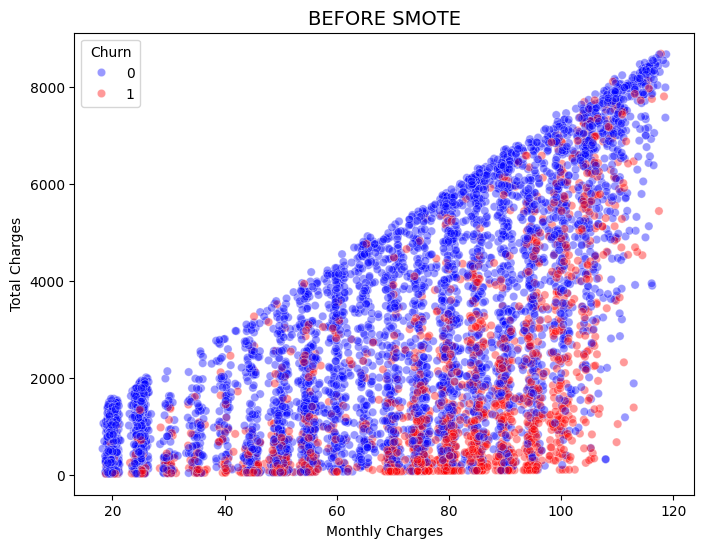

In [236]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='MonthlyCharges', y='TotalCharges', hue='Churn', palette={0: 'blue', 1: 'red'}, alpha=0.4)

plt.title('BEFORE SMOTE', fontsize=14)
plt.xlabel('Monthly Charges')
plt.ylabel('Total Charges')
plt.show()

In [237]:
from imblearn.over_sampling import SMOTE
#spliting features from  target
X=df.drop('Churn', axis=1)
y=df['Churn']
#Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)
X_resampled.shape

(10348, 27)

In [238]:
df2=pd.DataFrame(X_resampled, columns=X.columns)
df2['Churn']=y_resampled # add the target column
df2.shape

(10348, 28)

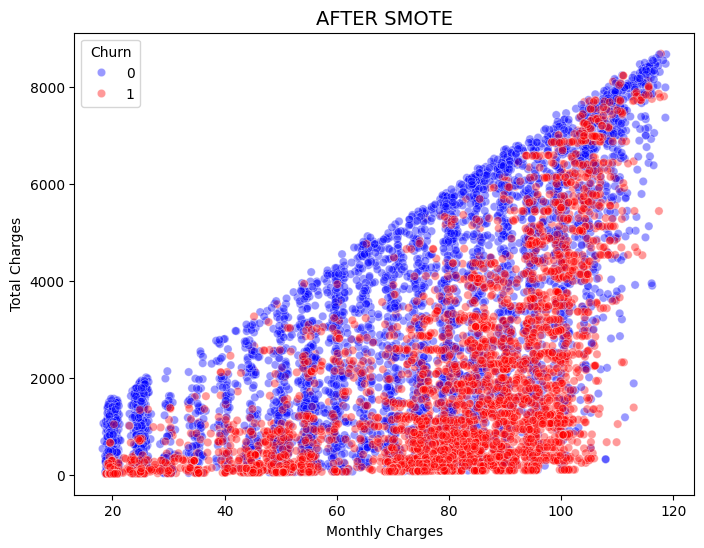

In [239]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(8,6))
sns.scatterplot( data=df2, x='MonthlyCharges', y='TotalCharges', hue='Churn', palette={0: 'blue', 1: 'red'}, alpha=0.4)

plt.title('AFTER SMOTE', fontsize=14)
plt.xlabel('Monthly Charges')
plt.ylabel('Total Charges')
plt.legend(title='Churn')
plt.show()

In [240]:
print(df2['Churn'].value_counts())

Churn
0    5174
1    5174
Name: count, dtype: int64


## Feature Selection we have tooooo many features

##Correlation

In [241]:
df["DeviceProtection_Yes"].value_counts()

,count
DeviceProtection_Yes,
False,4621
True,2422


In [242]:
#To see correltion with target feature Churn
corr_table = df2.corr()['Churn'].sort_values(ascending=False)
print(corr_table)

Churn                                    1.000000
PaymentMethod_Electronic check           0.465680
InternetService_Fiber optic              0.389054
MonthlyCharges                           0.242742
MultipleLines_Yes                        0.155055
PaperlessBilling                         0.121270
Streaming                                0.029969
DeviceProtection_Yes                     0.025350
MultipleLines_No phone service           0.017082
SeniorCitizen                            0.016715
OnlineBackup_Yes                         0.006599
PhoneService                            -0.017082
PaymentMethod_Mailed check              -0.046446
PaymentMethod_Credit card (automatic)   -0.079781
OnlineSecurity_Yes                      -0.108177
TechSupport_Yes                         -0.111558
Contract_One year                       -0.156584
gender                                  -0.163549
TotalCharges                            -0.229966
TechSupport_No internet service         -0.285147


In [243]:
#dropped the features with least effect on churn
modelDF=df2.copy()
modelDF.columns
modelDF.drop('gender', axis=1, inplace=True)
modelDF.drop('Partner', axis=1, inplace=True)
modelDF.drop('Dependents', axis=1, inplace=True)
modelDF.drop('DeviceProtection_Yes', axis=1, inplace=True)
modelDF.drop('DeviceProtection_No internet service', axis=1, inplace=True)

model_X=modelDF.drop('Churn', axis=1)
model_y=modelDF['Churn']

In [244]:
print(modelDF.dtypes)
modelDF.shape

SeniorCitizen                              int64
tenure                                     int64
PhoneService                               int64
PaperlessBilling                           int64
MonthlyCharges                           float64
TotalCharges                             float64
MultipleLines_No phone service              bool
MultipleLines_Yes                           bool
InternetService_Fiber optic                 bool
InternetService_No                          bool
OnlineSecurity_No internet service          bool
OnlineSecurity_Yes                          bool
OnlineBackup_No internet service            bool
OnlineBackup_Yes                            bool
TechSupport_No internet service             bool
TechSupport_Yes                             bool
Contract_One year                           bool
Contract_Two year                           bool
PaymentMethod_Credit card (automatic)       bool
PaymentMethod_Electronic check              bool
PaymentMethod_Mailed

(10348, 23)

## Clustering

In [245]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

In [246]:
df['Churn']=df['Churn'].map({'Yes':1, 'No':0})

X=modelDF.drop(columns=["Churn"])

#Scale features
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

## We need to choose how many clusters so we used two ways

1. Elbow method

Inertia is how close/tightly grouped the clusters are. the smaller then the points are closer to the center cluster


In [247]:
inertia=[]

for k in range(2, 10):
    km=KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

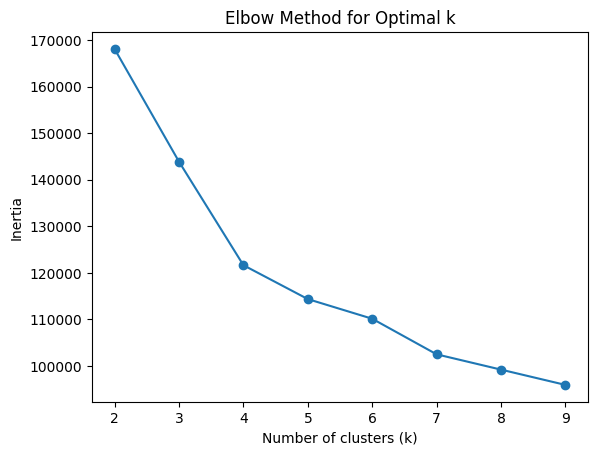

In [248]:
# Plot elbow method
plt.figure()
plt.plot(range(2, 10), inertia, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

### way 2: silhouette score
it showed k=2 as optimal while elbow method shows k=4 optimal. but choosing k=2 simplifies the data and groups alll the customers into two categories only. k=4 is broader and allows more insights.

In [249]:
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k}, Silhouette Score={score:.3f}")

k=2, Silhouette Score=0.332
k=3, Silhouette Score=0.225
k=4, Silhouette Score=0.258
k=5, Silhouette Score=0.233
k=6, Silhouette Score=0.203
k=7, Silhouette Score=0.188


In [250]:
kmeans = KMeans(n_clusters=4, random_state=42)
modelDF["Cluster"] = kmeans.fit_predict(X_scaled)

Because the dataset has so many features we used PCA for dimentionality reduction. it reduced many features and keeps maximum vairance. each dot is a customer.

purple = cluster 0, blue = cluster 1, green = cluster 2, yellow=cluster 3

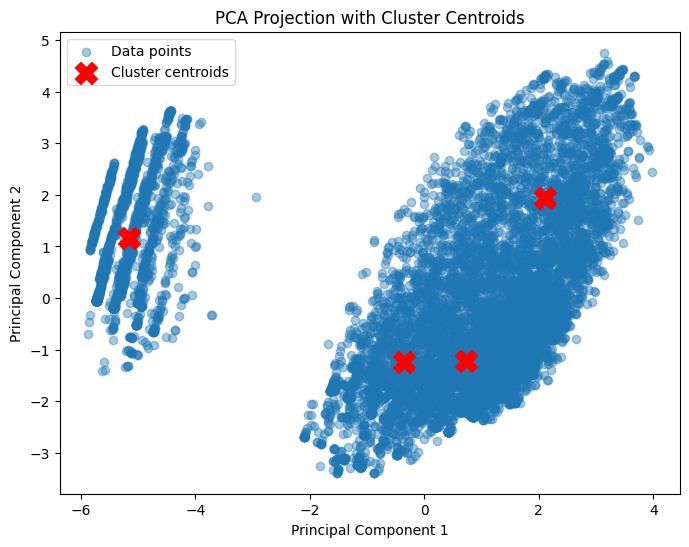

In [251]:
#PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

#visualize the centroids with the data points
centroids_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.4, label='Data points')
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='X', s=250,color='red', label='Cluster centroids')

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection with Cluster Centroids")
plt.legend()
plt.show()

In [252]:
cluster_profile=modelDF.groupby("Cluster").mean()
cluster_profile

,SeniorCitizen,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,...,OnlineBackup_Yes,TechSupport_No internet service,TechSupport_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Streaming,Churn
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.159755,13.031052,1.000000,0.678652,77.034862,1050.469830,0.000000,0.520123,0.752809,0.0,...,0.292543,0.0,0.179571,0.049847,0.004699,0.137283,0.682329,0.202043,0.472319,0.710317
1,0.030127,27.811124,0.966976,0.283314,21.243863,606.372201,0.033024,0.210892,0.000000,1.0,...,0.010429,1.0,0.005214,0.225377,0.376014,0.207995,0.114716,0.513326,0.000000,0.181344
2,0.158167,54.751293,1.000000,0.662232,91.915642,5079.177201,0.000000,0.769401,0.695492,0.0,...,0.729490,0.0,0.610495,0.422395,0.365484,0.363636,0.358093,0.092018,0.833703,0.323356
3,0.126347,25.943193,0.000000,0.543585,42.435358,1242.187328,1.000000,0.050930,0.036239,0.0,...,0.412341,0.0,0.398629,0.196866,0.158668,0.220372,0.478942,0.275220,0.453477,0.498531


Clustering:
If 0 -> High risk customer 71% churn

If 1 -> Low risk but needs attention 32% churn

If 2 -> Low risk loyal customer 18% churn

If 3 -> mid risk customer 50% churn

In [253]:
cluster_mapping = {
   0: "high risk",
   1: "loyal low risk",
   2:  "low risk needs attention",
   3: "mid risk"}
modelDF['cluster_profile'] = modelDF['Cluster'].map(cluster_mapping)

In [254]:
ClusterProfile=modelDF.groupby("cluster_profile").mean()
ClusterProfile

,SeniorCitizen,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,...,TechSupport_No internet service,TechSupport_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Streaming,Churn,Cluster
cluster_profile,,,,,,,,,,,,,,,,,,,,,
high risk,0.159755,13.031052,1.000000,0.678652,77.034862,1050.469830,0.000000,0.520123,0.752809,0.0,...,0.0,0.179571,0.049847,0.004699,0.137283,0.682329,0.202043,0.472319,0.710317,0.0
low risk needs attention,0.158167,54.751293,1.000000,0.662232,91.915642,5079.177201,0.000000,0.769401,0.695492,0.0,...,0.0,0.610495,0.422395,0.365484,0.363636,0.358093,0.092018,0.833703,0.323356,2.0
loyal low risk,0.030127,27.811124,0.966976,0.283314,21.243863,606.372201,0.033024,0.210892,0.000000,1.0,...,1.0,0.005214,0.225377,0.376014,0.207995,0.114716,0.513326,0.000000,0.181344,1.0
mid risk,0.126347,25.943193,0.000000,0.543585,42.435358,1242.187328,1.000000,0.050930,0.036239,0.0,...,0.0,0.398629,0.196866,0.158668,0.220372,0.478942,0.275220,0.453477,0.498531,3.0


In [255]:
import matplotlib.patches as mpatches

color_map = {
    "high risk": "red",
    "loyal low risk": "green",
    "low risk needs attention": "orange",
    "mid risk": "blue"
}

colors = modelDF['cluster_profile'].map(color_map)

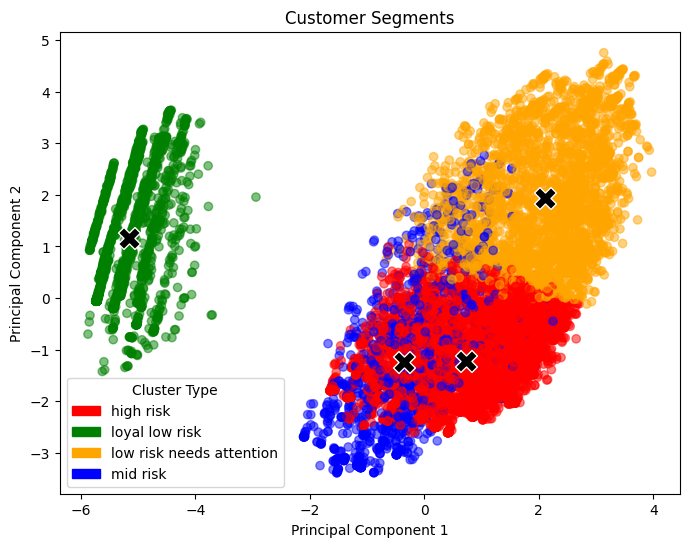

In [261]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=colors, alpha=0.5)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='X', s=250, color='black', edgecolor='white', label='Cluster centroids')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segments")

# Create legend manually
legend_handles = [
    mpatches.Patch(color=color, label=label)
    for label, color in color_map.items()
]

plt.legend(handles=legend_handles, title="Cluster Type")
plt.show()

## For k=3

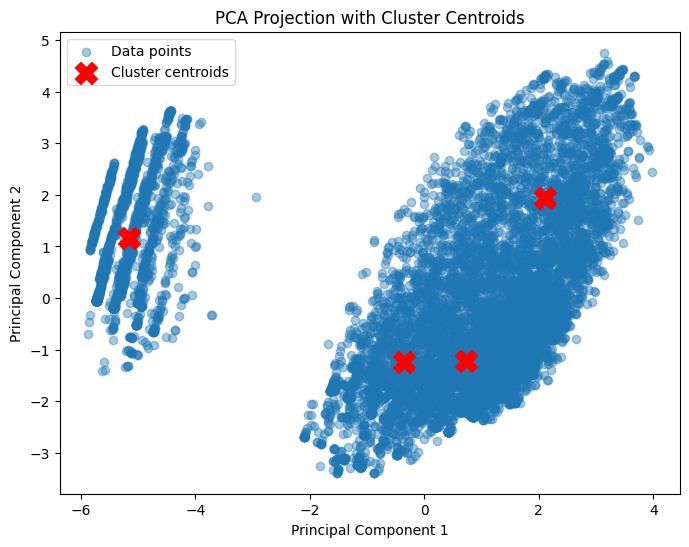

In [257]:
kmeansTry2 = KMeans(n_clusters=3, random_state=42)
modelDF['ClusterTry2'] = kmeansTry2.fit_predict(X_scaled)

#PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

#visualize the centroids with the data points
centroids_pcaTry2 = pca.transform(kmeansTry2.cluster_centers_)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.4, label='Data points')
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='X', s=250,color='red', label='Cluster centroids')

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection with Cluster Centroids")
plt.legend()
plt.show()

In [258]:
clusterlabels={
    0: "high risk",
    1: "loyal low risk",
    2: "medium risk"
}

modelDF['ClusterLabelTry2'] = modelDF['ClusterTry2'].map(clusterlabels)


In [259]:
color_map_3={
    "high risk": "red",
    "loyal low risk": "green",
    "medium risk": "orange"}
colorsTry2 = modelDF['ClusterLabelTry2'].map(color_map_3)

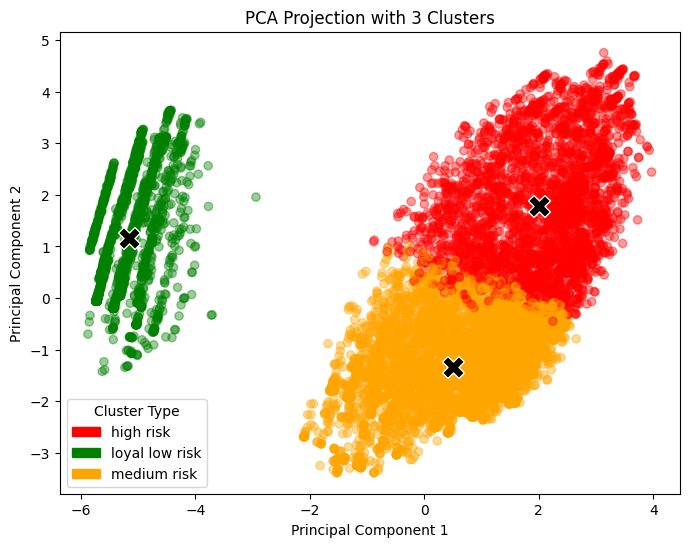

In [260]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=colorsTry2, alpha=0.4)

# Centroids
plt.scatter(centroids_pcaTry2[:, 0], centroids_pcaTry2[:, 1], marker='X', s=250, color='black', edgecolor='white', label='Cluster centroids')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection with 3 Clusters")

legend_handles = [
    mpatches.Patch(color=color, label=label)
    for label, color in color_map_3.items()]

plt.legend(handles=legend_handles, title="Cluster Type")
plt.show()
